In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### 1. Load the customers CSV

In [38]:

from pathlib import Path


DATA_DIR = Path("../data")

customers_df = pd.read_csv(DATA_DIR / "customers_raw.csv")

customers_df.head()


,customer_id,gender,age,city,plan_type,contract_type,tenure_months,internet_service,device_type,auto_pay,family_lines,roaming
0,C00001,Male,31.0,Lusail,Standard,One year,67,5G,Router,Yes,1,No
1,C00002,Female,26.0,Al Rayyan,Standard,Month-to-month,58,4G,Router,No,2,No
2,C00003,Female,24.0,Al Khor,Basic,Month-to-month,16,5G,Android,No,3,No
3,C00004,Male,24.0,Al Wakrah,Premium,Month-to-month,13,5G,iPhone,Yes,4,No
4,C00005,Male,61.0,Doha,Basic,Month-to-month,25,4G,Android,Yes,4,Yes


#### 2. Understand the dataset

In [39]:

print("Dataset shape:", customers_df.shape)

print("\nColumn names:")
print(customers_df.columns.tolist())

print("\nData types and non-null counts:")
customers_df.info()

print("\nMissing values:")
print(customers_df.isnull().sum())

print("\nDuplicate rows:", customers_df.duplicated().sum())


Dataset shape: (12035, 12)

Column names:
['customer_id', 'gender', 'age', 'city', 'plan_type', 'contract_type', 'tenure_months', 'internet_service', 'device_type', 'auto_pay', 'family_lines', 'roaming']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 12035 entries, 0 to 12034
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       12035 non-null  str    
 1   gender            12035 non-null  str    
 2   age               11954 non-null  float64
 3   city              12035 non-null  str    
 4   plan_type         12035 non-null  str    
 5   contract_type     12035 non-null  str    
 6   tenure_months     12035 non-null  int64  
 7   internet_service  11353 non-null  str    
 8   device_type       12035 non-null  str    
 9   auto_pay          11985 non-null  str    
 10  family_lines      12035 non-null  int64  
 11  roaming           12035 non-null  str    
dtypes:

#### 3. Check missing values

In [40]:

# Count missing values in each column
customers_df.isnull().sum()


customer_id           0
gender                0
age                  81
city                  0
plan_type             0
contract_type         0
tenure_months         0
internet_service    682
device_type           0
auto_pay             50
family_lines          0
roaming               0
dtype: int64

#### 4. Check duplicate records

In [41]:

# Count rows that are exact duplicates
customers_df.duplicated().sum()


np.int64(35)

Is Customer ID column having duplicates?

In [42]:

# Count occurrences of each customer ID
#customers_df["customer_id"].value_counts().head(10)

# Count occurrences of each customer ID
customers_df["customer_id"].duplicated().value_counts()



customer_id
False    12000
True        35
Name: count, dtype: int64

Why both checks? Two rows can share a customer ID without being identical across every column. We need to investigate that before merging datasets.

#### 5. Inspect categorical columns

In [43]:

print("Cities:")
print(customers_df["city"].value_counts(dropna=False))

print("\nPlan types:")
print(customers_df["plan_type"].value_counts(dropna=False))

print("\nAuto-pay values:")
print(customers_df["auto_pay"].value_counts(dropna=False))


Cities:
city
Doha         4228
Al Rayyan    2599
Al Wakrah    1689
Lusail       1430
Al Khor      1156
Umm Salal     822
Lusail         26
doha           25
Al-Rayyan      24
DOHA           18
AL WAKRAH      18
Name: count, dtype: int64

Plan types:
plan_type
Standard     5396
Basic        4156
Premium      2423
premium        24
Standard       18
 BASIC         18
Name: count, dtype: int64

Auto-pay values:
auto_pay
Yes    7440
No     4545
NaN      50
Name: count, dtype: int64


#### 6. Cleaning the dataset

##### a. Inspect the duplicate records

In [44]:
# Display all rows with duplicated records
duplicated_rows = customers_df[customers_df["customer_id"].duplicated(keep=False)].sort_values("customer_id")
duplicated_rows

,customer_id,gender,age,city,plan_type,contract_type,tenure_months,internet_service,device_type,auto_pay,family_lines,roaming
328,C00329,Female,56.0,Al Wakrah,Basic,Month-to-month,21,5G,Android,Yes,5,No
12023,C00329,Female,56.0,Al Wakrah,Basic,Month-to-month,21,5G,Android,Yes,5,No
437,C00438,Male,49.0,Al Rayyan,Basic,Month-to-month,43,4G,iPhone,Yes,4,No
12000,C00438,Male,49.0,Al Rayyan,Basic,Month-to-month,43,4G,iPhone,Yes,4,No
485,C00486,Male,18.0,Al Rayyan,Standard,Month-to-month,7,4G,Other,Yes,4,No
...,...,...,...,...,...,...,...,...,...,...,...,...
11351,C11352,Female,31.0,Al-Rayyan,Basic,Month-to-month,18,5G,Android,No,5,No
12020,C11582,Female,48.0,Lusail,Basic,Two year,60,5G,Android,Yes,1,No
11581,C11582,Female,48.0,Lusail,Basic,Two year,60,5G,Android,Yes,1,No
12009,C11992,Male,NaN,Doha,Standard,Month-to-month,64,4G,Android,No,3,No


#### b. Remove exact duplicates

In [45]:
customer_df = customers_df.drop_duplicates()
customer_df

,customer_id,gender,age,city,plan_type,contract_type,tenure_months,internet_service,device_type,auto_pay,family_lines,roaming
0,C00001,Male,31.0,Lusail,Standard,One year,67,5G,Router,Yes,1,No
1,C00002,Female,26.0,Al Rayyan,Standard,Month-to-month,58,4G,Router,No,2,No
2,C00003,Female,24.0,Al Khor,Basic,Month-to-month,16,5G,Android,No,3,No
3,C00004,Male,24.0,Al Wakrah,Premium,Month-to-month,13,5G,iPhone,Yes,4,No
4,C00005,Male,61.0,Doha,Basic,Month-to-month,25,4G,Android,Yes,4,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...
11995,C11996,Female,50.0,Lusail,Basic,Month-to-month,49,4G,iPhone,No,4,No
11996,C11997,Female,38.0,Doha,Standard,Month-to-month,26,5G,Other,Yes,1,No
11997,C11998,Male,36.0,Al Rayyan,Standard,Month-to-month,51,5G,iPhone,No,1,No
11998,C11999,Female,31.0,Lusail,Basic,Two year,13,4G,iPhone,Yes,5,Yes


#### c. Standardize the categorical column values; city and plan types

In [46]:
# Standardize city names
customers_df["city"]= (customers_df["city"].str.strip().str.title().replace({"Al-Rayyan": "Al Rayyan", "Al-Wakrah": "Al Wakrah"}))

# Standardize plan types
customers_df["plan_type"]= (customers_df["plan_type"].str.strip().str.title())
print(customers_df["city"].value_counts(dropna=False))
print()
print(customers_df["plan_type"].value_counts(dropna=False))

city
Doha         4271
Al Rayyan    2623
Al Wakrah    1707
Lusail       1456
Al Khor      1156
Umm Salal     822
Name: count, dtype: int64

plan_type
Standard    5414
Basic       4174
Premium     2447
Name: count, dtype: int64


#### d. Handling missing values

In [47]:
print(customer_df["internet_service"].value_counts(dropna=False))
print("\nMissing values")
print(customer_df[["internet_service","age","auto_pay"]].isnull().sum())

internet_service
Fiber    4264
5G       3682
4G       3376
NaN       678
Name: count, dtype: int64

Missing values
internet_service    678
age                  80
auto_pay             50
dtype: int64


#### e. Validate age and tenure

In [48]:
# Check for invalid values in the "age" column
print("Age Summary")
print(customer_df["age"].describe())

print("\nInvalid ages")
print(customer_df[customer_df["age"]<18|(customer_df["age"]>80)])

print("\nTenure Summary")
print(customer_df["tenure_months"].describe())

Age Summary
count    11920.000000
mean        36.108725
std         10.405275
min         18.000000
25%         29.000000
50%         36.000000
75%         43.000000
max         80.000000
Name: age, dtype: float64

Invalid ages
Empty DataFrame
Columns: [customer_id, gender, age, city, plan_type, contract_type, tenure_months, internet_service, device_type, auto_pay, family_lines, roaming]
Index: []

Tenure Summary
count    12000.000000
mean        36.770500
std         20.791285
min          1.000000
25%         19.000000
50%         37.000000
75%         55.000000
max         72.000000
Name: tenure_months, dtype: float64


#### f. Handling missing values

In [49]:

# Fill missing age values with the median
customers_df["age"] = customers_df["age"].fillna(
    customers_df["age"].median()
)

# Preserve missing categories as Unknown
customers_df["internet_service"] = customers_df["internet_service"].fillna("Unknown")


customers_df["auto_pay"] = customers_df["auto_pay"].fillna("Unknown")


print("Missing values after cleaning:")
print(customers_df[["age", "internet_service", "auto_pay"]].isnull().sum())


Missing values after cleaning:
age                 0
internet_service    0
auto_pay            0
dtype: int64


#### g. final check

In [51]:
customers_df = customers_df.drop_duplicates().copy()
print("Final shape:", customers_df.shape)
print("Duplicate rows:", customers_df.duplicated().sum())
print("Unique customer IDs:", customers_df["customer_id"].nunique())
print("Missing values:", customers_df.isnull().sum().sum())

customers_df.head()


Final shape: (12000, 12)
Duplicate rows: 0
Unique customer IDs: 12000
Missing values: 0


,customer_id,gender,age,city,plan_type,contract_type,tenure_months,internet_service,device_type,auto_pay,family_lines,roaming
0,C00001,Male,31.0,Lusail,Standard,One year,67,5G,Router,Yes,1,No
1,C00002,Female,26.0,Al Rayyan,Standard,Month-to-month,58,4G,Router,No,2,No
2,C00003,Female,24.0,Al Khor,Basic,Month-to-month,16,5G,Android,No,3,No
3,C00004,Male,24.0,Al Wakrah,Premium,Month-to-month,13,5G,iPhone,Yes,4,No
4,C00005,Male,61.0,Doha,Basic,Month-to-month,25,4G,Android,Yes,4,Yes


#### Save cleaned dataset to data folder

In [52]:
customers_cleaned = customers_df.copy()
customers_cleaned.to_csv(DATA_DIR / "customers_cleaned.csv", index=False)

## Second dataset: Usage_raw

#### 1. Load the usage dataset

In [53]:

usage_df = pd.read_csv(DATA_DIR / "usage_raw.csv")

usage_df.head()


,customer_id,voice_minutes_monthly,data_usage_gb_monthly,sms_count_monthly,international_minutes_monthly,dropped_calls_monthly,network_incidents
0,C00001,437.0,6.51,73,9.66,3,1
1,C00002,165.0,6.72,62,34.65,2,3
2,C00003,395.0,9.59,54,8.02,4,0
3,C00004,216.0,28.93,66,15.27,3,0
4,C00005,367.0,17.74,71,8.10,2,1


#### 2. Understand the dataset

In [54]:

print("Dataset shape:", usage_df.shape)

print("\nColumn names:")
print(usage_df.columns.tolist())

print("\nData types:")
usage_df.info()


Dataset shape: (11980, 7)

Column names:
['customer_id', 'voice_minutes_monthly', 'data_usage_gb_monthly', 'sms_count_monthly', 'international_minutes_monthly', 'dropped_calls_monthly', 'network_incidents']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 11980 entries, 0 to 11979
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   customer_id                    11980 non-null  str    
 1   voice_minutes_monthly          11980 non-null  float64
 2   data_usage_gb_monthly          11889 non-null  float64
 3   sms_count_monthly              11980 non-null  int64  
 4   international_minutes_monthly  11980 non-null  float64
 5   dropped_calls_monthly          11980 non-null  int64  
 6   network_incidents              11980 non-null  int64  
dtypes: float64(3), int64(3), str(1)
memory usage: 655.3 KB


### 3. Check missing values and duplicates

In [55]:

print("Missing values:")
print(usage_df.isnull().sum())

print("\nExact duplicate rows:")
print(usage_df.duplicated().sum())

print("\nDuplicate customer IDs:")
print(usage_df["customer_id"].duplicated().sum())


Missing values:
customer_id                       0
voice_minutes_monthly             0
data_usage_gb_monthly            91
sms_count_monthly                 0
international_minutes_monthly     0
dropped_calls_monthly             0
network_incidents                 0
dtype: int64

Exact duplicate rows:
25

Duplicate customer IDs:
25


### 4. Check for invalid values

In [56]:

numeric_cols = [
    "voice_minutes_monthly",
    "data_usage_gb_monthly",
    "sms_count_monthly",
    "international_minutes_monthly",
    "dropped_calls_monthly",
    "network_incidents"
]

print(usage_df[numeric_cols].describe())

print("\nNegative values by column:")
print((usage_df[numeric_cols] < 0).sum())


       voice_minutes_monthly  data_usage_gb_monthly  sms_count_monthly  \
count           11980.000000           11889.000000       11980.000000   
mean              319.642988              16.554296          64.897579   
std               140.116750              10.425534           8.115584   
min                 0.000000               0.030000          32.000000   
25%               223.000000               8.830000          59.000000   
50%               318.000000              14.700000          65.000000   
75%               415.000000              22.130000          70.000000   
max               877.000000              96.070000          97.000000   

       international_minutes_monthly  dropped_calls_monthly  network_incidents  
count                   11980.000000           11980.000000       11980.000000  
mean                       27.084408               2.008848           1.188731  
std                        22.153395               1.421487           1.085319  
min      

### 5. Investigate the invalid dropped-call values

In [57]:

usage_df.loc[
    usage_df["dropped_calls_monthly"] < 0,
    ["customer_id", "dropped_calls_monthly"]
]


,customer_id,dropped_calls_monthly
374,C00375,-1
439,C00441,-1
566,C00570,-1
974,C00978,-1
1223,C01228,-1
2818,C02826,-1
2869,C02877,-1
2946,C02954,-1
3706,C03716,-1
4219,C04231,-1


### 6. Fix the invalid values and missing data

In [58]:

# Replace impossible negative dropped-call counts with missing values
usage_df.loc[
    usage_df["dropped_calls_monthly"] < 0,
    "dropped_calls_monthly"
] = np.nan

# Fill missing data usage with its median
usage_df["data_usage_gb_monthly"] = (
    usage_df["data_usage_gb_monthly"].fillna(
        usage_df["data_usage_gb_monthly"].median()
    )
)

# Fill invalid dropped-call counts with their median
usage_df["dropped_calls_monthly"] = (
    usage_df["dropped_calls_monthly"].fillna(
        usage_df["dropped_calls_monthly"].median()
    )
)

print("Missing values remaining:", usage_df.isnull().sum().sum())
print(
    "Negative dropped-call counts remaining:",
    (usage_df["dropped_calls_monthly"] < 0).sum()
)


Missing values remaining: 0
Negative dropped-call counts remaining: 0


Since dropped calls are counts, let's also convert that column back to an integer type after imputation:

In [59]:
usage_df["dropped_calls_monthly"] = (
    usage_df["dropped_calls_monthly"].round().astype(int)
)

### 7. Check duplicates

In [60]:
print("Exact duplicate rows:", usage_df.duplicated().sum())
print("Duplicate customer IDs:", usage_df["customer_id"].duplicated().sum())

Exact duplicate rows: 25
Duplicate customer IDs: 25


### 8. Remove duplicate records

In [61]:

usage_df = usage_df.drop_duplicates().copy()

print("Final shape:", usage_df.shape)
print("Exact duplicate rows:", usage_df.duplicated().sum())
print("Unique customer IDs:", usage_df["customer_id"].nunique())
print("Missing values:", usage_df.isnull().sum().sum())


Final shape: (11955, 7)
Exact duplicate rows: 0
Unique customer IDs: 11955
Missing values: 0


#### Save cleaned data- usage

In [62]:

usage_df.to_csv("../data/usage_clean.csv", index=False)


### Third dataset- billing_raw.csv

#### 1. Load dataset

In [63]:

billing_df = pd.read_csv(DATA_DIR / "billing_raw.csv")

billing_df.head()


,customer_id,monthly_charges_qar,total_charges_qar,payment_delay_count
0,C00001,271.95,18162.63,1
1,C00002,276.34,16289.71,1
2,C00003,188.66,2977.98,0
3,C00004,611.28,7927.12,0
4,C00005,281.05,7302.23,0


#### 2. Understand the dataset

In [64]:

print("Dataset shape:", billing_df.shape)

print("\nColumn names:")
print(billing_df.columns.tolist())

print("\nData types:")
billing_df.info()


Dataset shape: (11965, 4)

Column names:
['customer_id', 'monthly_charges_qar', 'total_charges_qar', 'payment_delay_count']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 11965 entries, 0 to 11964
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          11965 non-null  str    
 1   monthly_charges_qar  11895 non-null  float64
 2   total_charges_qar    11965 non-null  float64
 3   payment_delay_count  11965 non-null  int64  
dtypes: float64(2), int64(1), str(1)
memory usage: 374.0 KB


#### 3. Profile data quality

In [65]:

print("Missing values:")
print(billing_df.isnull().sum())

print("\nExact duplicate rows:", billing_df.duplicated().sum())

print("\nDuplicate customer IDs:",
      billing_df["customer_id"].duplicated().sum())


Missing values:
customer_id             0
monthly_charges_qar    70
total_charges_qar       0
payment_delay_count     0
dtype: int64

Exact duplicate rows: 20

Duplicate customer IDs: 20


#### 4. Inspect the billing values

In [66]:

print(billing_df[[
    "monthly_charges_qar",
    "total_charges_qar",
    "payment_delay_count"
]].describe())

print("\nNegative values by column:")
print(
    (billing_df[[
        "monthly_charges_qar",
        "total_charges_qar",
        "payment_delay_count"
    ]] < 0).sum()
)


       monthly_charges_qar  total_charges_qar  payment_delay_count
count         11895.000000       11965.000000         11965.000000
mean            335.046034       12160.238685             0.634852
std             132.162734        8684.450396             0.796372
min            -661.850000         120.490000             0.000000
25%             238.305000        5381.400000             0.000000
50%             315.230000       10589.110000             0.000000
75%             395.365000       17051.420000             1.000000
max             838.330000       50788.680000             7.000000

Negative values by column:
monthly_charges_qar    35
total_charges_qar       0
payment_delay_count     0
dtype: int64


#### 5. Investigate missing monthly charges

In [67]:

billing_df.loc[
    billing_df["monthly_charges_qar"].isnull(),
    ["customer_id", "monthly_charges_qar", "total_charges_qar",
     "payment_delay_count"]
].head(10)


,customer_id,monthly_charges_qar,total_charges_qar,payment_delay_count
76,C00078,NaN,21389.40,0
152,C00154,NaN,21975.98,1
238,C00240,NaN,31020.63,1
392,C00395,NaN,3641.81,0
480,C00483,NaN,13228.92,1
575,C00579,NaN,9895.52,1
790,C00794,NaN,2417.58,0
899,C00904,NaN,32388.84,1
1143,C01150,NaN,6673.77,0
1290,C01298,NaN,12960.87,2


#### 6. Remove exact duplicates

In [68]:

billing_df = billing_df.drop_duplicates().copy()

print("Shape after removing duplicates:", billing_df.shape)
print("Remaining exact duplicates:", billing_df.duplicated().sum())
print("Unique customer IDs:", billing_df["customer_id"].nunique())


Shape after removing duplicates: (11945, 4)
Remaining exact duplicates: 0
Unique customer IDs: 11945


#### 7. Investigate the invalid charges

In [69]:

billing_df.loc[
    billing_df["monthly_charges_qar"] < 0,
    ["customer_id", "monthly_charges_qar",
     "total_charges_qar", "payment_delay_count"]
]


,customer_id,monthly_charges_qar,total_charges_qar,payment_delay_count
1348,C01356,-472.81,6973.39,0
1391,C01399,-311.93,14766.17,1
1566,C01575,-295.54,18020.67,1
1600,C01609,-184.67,10824.32,1
1898,C01912,-217.87,11334.85,0
1994,C02008,-661.85,5265.73,0
2019,C02034,-332.52,3385.53,0
2047,C02062,-347.17,424.63,0
2139,C02154,-361.73,10822.59,0
2545,C02562,-257.66,19516.72,0


#### 8. Correct missing and invalid monthly charges

In [75]:

# Replace invalid negative monthly charges with NaN
billing_df.loc[
    billing_df["monthly_charges_qar"] < 0,
    "monthly_charges_qar"
] = np.nan

# Calculate the median from valid monthly charges
median_charge = billing_df["monthly_charges_qar"].median()

# Fill missing and invalid monthly charges
billing_df["monthly_charges_qar"] = (
    billing_df["monthly_charges_qar"].fillna(median_charge)
)

print("Median monthly charge used:", round(median_charge, 2))
print("Missing values remaining:", billing_df.isnull().sum().sum())
print(
    "Negative monthly charges remaining:",
    (billing_df["monthly_charges_qar"] < 0).sum()
)


Median monthly charge used: 315.66
Missing values remaining: 0
Negative monthly charges remaining: 0


For a production billing system, we'd ideally recover the actual amounts from the source rather than impute them.

#### 9. Remove exact duplicates

In [76]:

billing_df = billing_df.drop_duplicates().copy()

print("Final shape:", billing_df.shape)
print("Exact duplicates:", billing_df.duplicated().sum())
print("Unique customer IDs:", billing_df["customer_id"].nunique())
print("Missing values:", billing_df.isnull().sum().sum())


Final shape: (11945, 4)
Exact duplicates: 0
Unique customer IDs: 11945
Missing values: 0


#### 10. Save the cleaned billing data

In [77]:

billing_df.to_csv("../data/billing_clean.csv", index=False)


### Fourth dataset - Support_raw.csv

#### 1. Load the support dataset

In [78]:

support_df = pd.read_csv(DATA_DIR / "support_raw.csv")

support_df.head()


,customer_id,complaints_count,support_contacts
0,C00001,1.0,1
1,C00002,0.0,0
2,C00003,0.0,1
3,C00004,2.0,2
4,C00005,1.0,2


#### 2. Understand the dataset

In [79]:

print("Dataset shape:", support_df.shape)

print("\nColumn names:")
print(support_df.columns.tolist())

print("\nData types:")
support_df.info()


Dataset shape: (11920, 3)

Column names:
['customer_id', 'complaints_count', 'support_contacts']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 11920 entries, 0 to 11919
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       11920 non-null  str    
 1   complaints_count  11845 non-null  float64
 2   support_contacts  11920 non-null  int64  
dtypes: float64(1), int64(1), str(1)
memory usage: 279.5 KB


#### 3. Profile data quality

In [80]:

print("Missing values:")
print(support_df.isnull().sum())

print("\nExact duplicate rows:", support_df.duplicated().sum())

print("\nDuplicate customer IDs:",
      support_df["customer_id"].duplicated().sum())

print("\nSummary statistics:")
support_df.describe()


Missing values:
customer_id          0
complaints_count    75
support_contacts     0
dtype: int64

Exact duplicate rows: 0

Duplicate customer IDs: 0

Summary statistics:


,complaints_count,support_contacts
count,11845.000000,11920.000000
mean,0.830646,1.526007
std,0.915654,1.236384
min,0.000000,0.000000
25%,0.000000,1.000000
50%,1.000000,1.000000
75%,1.000000,2.000000
max,6.000000,9.000000


#### 4. Handle missing complaint counts

In [83]:

support_df.loc[
    support_df["complaints_count"].isnull()
].head(10)


,customer_id,complaints_count,support_contacts
6,C00007,NaN,3
12,C00013,NaN,2
233,C00236,NaN,1
349,C00353,NaN,1
466,C00470,NaN,1
527,C00531,NaN,1
592,C00596,NaN,2
766,C00771,NaN,2
863,C00869,NaN,0
888,C00894,NaN,2


In [84]:

median_complaints = support_df["complaints_count"].median()

support_df["complaints_count"] = (
    support_df["complaints_count"].fillna(median_complaints)
)

print("Median complaints:", median_complaints)
print("Missing values remaining:", support_df.isnull().sum().sum())


Median complaints: 1.0
Missing values remaining: 0


#### Validate and save

In [85]:

print("Final shape:", support_df.shape)
print("Exact duplicates:", support_df.duplicated().sum())
print("Unique customer IDs:", support_df["customer_id"].nunique())
print("Missing values:", support_df.isnull().sum().sum())

support_df.to_csv("../data/support_clean.csv", index=False)


Final shape: (11920, 3)
Exact duplicates: 0
Unique customer IDs: 11920
Missing values: 0


### Fifth dataset - Churn target.csv

#### 1.load

In [86]:

churn_df = pd.read_csv(DATA_DIR / "churn_target_raw.csv")

churn_df.head()


,customer_id,churn
0,C00001,No
1,C00002,No
2,C00003,Yes
3,C00004,No
4,C00005,No


#### 2. Understand the dataset

In [87]:

print("Dataset shape:", churn_df.shape)

print("\nColumn names:")
print(churn_df.columns.tolist())

print("\nData types:")
churn_df.info()


Dataset shape: (12000, 2)

Column names:
['customer_id', 'churn']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   customer_id  12000 non-null  str  
 1   churn        12000 non-null  str  
dtypes: str(2)
memory usage: 187.6 KB


#### 3. Check data quality and the target distribution

In [88]:

print("Missing values:")
print(churn_df.isnull().sum())

print("\nExact duplicate rows:", churn_df.duplicated().sum())

print("\nDuplicate customer IDs:",
      churn_df["customer_id"].duplicated().sum())

print("\nChurn distribution:")
print(churn_df["churn"].value_counts(dropna=False))

print("\nChurn percentages:")
print(
    (churn_df["churn"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)


Missing values:
customer_id    0
churn          0
dtype: int64

Exact duplicate rows: 0

Duplicate customer IDs: 0

Churn distribution:
churn
No     10094
Yes     1906
Name: count, dtype: int64

Churn percentages:
churn
No     84.12
Yes    15.88
Name: proportion, dtype: float64


#### 4.Validate and save the churn dataset


In [89]:

print("Final shape:", churn_df.shape)
print("Unique customer IDs:", churn_df["customer_id"].nunique())
print("Missing values:", churn_df.isnull().sum().sum())
print("Duplicate rows:", churn_df.duplicated().sum())

churn_df.to_csv("../data/churn_target_clean.csv", index=False)


Final shape: (12000, 2)
Unique customer IDs: 12000
Missing values: 0
Duplicate rows: 0


### monthly_customer_revenue_raw.csv

#### 1.Load dataset

In [90]:

revenue_df = pd.read_csv(
    DATA_DIR / "monthly_customer_revenue_raw.csv"
)

revenue_df.head()


,customer_id,month,monthly_revenue_qar
0,C00001,2025-10-01,280.21
1,C00001,2025-11-01,259.14
2,C00001,2025-12-01,242.50
3,C00001,2026-01-01,271.97
4,C00001,2026-02-01,252.04


#### 2. Understand dataset

In [91]:

print("Dataset shape:", revenue_df.shape)

print("\nColumn names:")
print(revenue_df.columns.tolist())

print("\nData types:")
revenue_df.info()


Dataset shape: (143133, 3)

Column names:
['customer_id', 'month', 'monthly_revenue_qar']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 143133 entries, 0 to 143132
Data columns (total 3 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   customer_id          143133 non-null  str    
 1   month                143133 non-null  str    
 2   monthly_revenue_qar  143103 non-null  float64
dtypes: float64(1), str(2)
memory usage: 3.3 MB


#### 3. Check missing values and duplicates

In [92]:

print("Missing values:")
print(revenue_df.isnull().sum())

print("\nExact duplicate rows:")
print(revenue_df.duplicated().sum())

print("\nDuplicate customer IDs:")
print(revenue_df["customer_id"].duplicated().sum())


Missing values:
customer_id             0
month                   0
monthly_revenue_qar    30
dtype: int64

Exact duplicate rows:
0

Duplicate customer IDs:
131133


Important: duplicate customer IDs are expected here because a customer can appear in multiple months. We must not remove rows simply because their customer IDs repeat.

#### 4. Check revenue values and dates

In [93]:

print("Revenue summary:")
print(revenue_df["monthly_revenue_qar"].describe())

print("\nNegative revenue values:")
print((revenue_df["monthly_revenue_qar"] < 0).sum())

print("\nMonth examples:")
print(revenue_df["month"].head(10).tolist())

print("\nUnique months:", revenue_df["month"].nunique())


Revenue summary:
count    143103.000000
mean        340.545324
std         132.743843
min          75.310000
25%         240.320000
50%         316.600000
75%         409.625000
max         946.940000
Name: monthly_revenue_qar, dtype: float64

Negative revenue values:
0

Month examples:
['2025-10-01', '2025-11-01', '2025-12-01', '2026-01-01', '2026-02-01', '2026-03-01', '2026-04-01', '2026-05-01', '2026-06-01', '2026-07-01']

Unique months: 12


#### 5. Check for duplicate customer-month combinations

subset=["customer_id", "month"]
Tells Pandas to check only these two columns when identifying duplicates. The revenue amount is ignored for this check.

In [94]:

revenue_df.duplicated(
    subset=["customer_id", "month"]
).sum()


np.int64(0)

#### 6. convert month to a proper datetime column

In [95]:
# Convert month column to datetime
revenue_df["month"] = pd.to_datetime(
    revenue_df["month"],
    errors="coerce"
)

# Check the data type
print("Month data type:", revenue_df["month"].dtype)

# Check for invalid dates
print("Invalid dates:", revenue_df["month"].isna().sum())

# Check the date range
print("Earliest month:", revenue_df["month"].min())
print("Latest month:", revenue_df["month"].max())

Month data type: datetime64[us]
Invalid dates: 0
Earliest month: 2025-10-01 00:00:00
Latest month: 2026-09-01 00:00:00


errors="coerce"?
If Pandas encounters an invalid date, it converts it to NaT (Not a Time) rather than stopping with an error. We then check whether any invalid dates were created.

#### 7. Handle missing values

In [96]:
# Count missing revenue values
print("Missing revenue:", revenue_df["monthly_revenue_qar"].isna().sum())

# Check missing revenue by month
print("\nMissing revenue by month:")
print(
    revenue_df[revenue_df["monthly_revenue_qar"].isna()]
    .groupby("month")
    .size()
)

# Display a few rows with missing revenue
print("\nSample records with missing revenue:")
display(
    revenue_df[revenue_df["monthly_revenue_qar"].isna()].head(10)
)

Missing revenue: 30

Missing revenue by month:
month
2025-10-01    4
2025-11-01    2
2025-12-01    3
2026-01-01    2
2026-02-01    1
2026-03-01    3
2026-04-01    2
2026-05-01    2
2026-06-01    5
2026-07-01    3
2026-08-01    2
2026-09-01    1
dtype: int64

Sample records with missing revenue:


,customer_id,month,monthly_revenue_qar
18884,C01584,2026-02-01,NaN
20382,C01709,2026-09-01,NaN
21911,C01838,2025-12-01,NaN
28306,C02374,2026-08-01,NaN
31016,C02601,2026-07-01,NaN
39580,C03319,2026-01-01,NaN
40984,C03437,2025-10-01,NaN
41470,C03477,2026-06-01,NaN
41783,C03504,2025-10-01,NaN
46957,C03938,2025-10-01,NaN


In [97]:
# Calculate each customer's median monthly revenue
customer_median_revenue = (
    revenue_df.groupby("customer_id")["monthly_revenue_qar"]
    .transform("median")
)

# Fill missing values using each customer's median
revenue_df["monthly_revenue_qar"] = (
    revenue_df["monthly_revenue_qar"]
    .fillna(customer_median_revenue)
)

In [98]:
print("Missing revenue after filling:")
print(revenue_df["monthly_revenue_qar"].isna().sum())

print("\nRevenue summary after cleaning:")
print(revenue_df["monthly_revenue_qar"].describe())

Missing revenue after filling:
0

Revenue summary after cleaning:
count    143133.000000
mean        340.548596
std         132.742549
min          75.310000
25%         240.330000
50%         316.610000
75%         409.630000
max         946.940000
Name: monthly_revenue_qar, dtype: float64


#### Run the final validation

In [99]:
print("Final shape:", revenue_df.shape)

print("\nMissing values:")
print(revenue_df.isnull().sum())

print("\nExact duplicate rows:", revenue_df.duplicated().sum())

print(
    "Duplicate customer-month combinations:",
    revenue_df.duplicated(
        subset=["customer_id", "month"]
    ).sum()
)

print("\nUnique customers:", revenue_df["customer_id"].nunique())
print("Unique months:", revenue_df["month"].nunique())

print("\nData types:")
print(revenue_df.dtypes)

Final shape: (143133, 3)

Missing values:
customer_id            0
month                  0
monthly_revenue_qar    0
dtype: int64

Exact duplicate rows: 0
Duplicate customer-month combinations: 0

Unique customers: 12000
Unique months: 12

Data types:
customer_id                       str
month                  datetime64[us]
monthly_revenue_qar           float64
dtype: object


In [100]:
revenue_df.to_csv(
    "../data/monthly_customer_revenue_clean.csv",
    index=False
)

### Merging the cleaned datasets

#### 1. Load the datasets

In [102]:

from pathlib import Path

DATA_DIR = Path("../data")

customers_df = pd.read_csv(DATA_DIR / "customers_cleaned.csv")
usage_df = pd.read_csv(DATA_DIR / "usage_clean.csv")
billing_df = pd.read_csv(DATA_DIR / "billing_clean.csv")
support_df = pd.read_csv(DATA_DIR / "support_clean.csv")
churn_df = pd.read_csv(DATA_DIR / "churn_target_clean.csv")

revenue_df = pd.read_csv(
    DATA_DIR / "monthly_customer_revenue_clean.csv",
    parse_dates=["month"]
)

print("Customers:", customers_df.shape)
print("Usage:", usage_df.shape)
print("Billing:", billing_df.shape)
print("Support:", support_df.shape)
print("Churn:", churn_df.shape)
print("Monthly revenue:", revenue_df.shape)

Customers: (12000, 12)
Usage: (11955, 7)
Billing: (11945, 4)
Support: (11920, 3)
Churn: (12000, 2)
Monthly revenue: (143133, 3)


Important: Those missing records in usage, billing, and support don't mean the entire customer should be deleted. We'll preserve all 12,000 customers and investigate unmatched records after merging.

#### 2. Merge customers with usage

In [105]:
customer_analytics_df = customers_df.merge(
    usage_df,
    on="customer_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Shape after merge:", customer_analytics_df.shape)

print("\nMerge results:")
print(customer_analytics_df["_merge"].value_counts())

Shape after merge: (12000, 19)

Merge results:
_merge
both          11955
left_only        45
right_only        0
Name: count, dtype: int64


These are joins

Left = preserve the left table. Right = preserve the right table. Inner = matches only. Outer = everything.

The 45 customers without usage data have not been deleted. Their usage columns will contain missing values (NaN).

#### 2. Merge the billing data

In [106]:
customer_analytics_df = customer_analytics_df.merge(
    billing_df,
    on="customer_id",
    how="left",
    validate="one_to_one",
    indicator="billing_merge"
)

print("Shape after billing merge:", customer_analytics_df.shape)

print("\nBilling merge results:")
print(customer_analytics_df["billing_merge"].value_counts())

Shape after billing merge: (12000, 23)

Billing merge results:
billing_merge
both          11945
left_only        55
right_only        0
Name: count, dtype: int64


we use indicator="billing_merge" instead of indicator=True. Pandas has already created the _merge column from our first merge, so a new indicator name avoids a column-name conflict.

In [107]:
customer_analytics_df.head()

,customer_id,gender,age,city,plan_type,contract_type,tenure_months,internet_service,device_type,auto_pay,...,data_usage_gb_monthly,sms_count_monthly,international_minutes_monthly,dropped_calls_monthly,network_incidents,_merge,monthly_charges_qar,total_charges_qar,payment_delay_count,billing_merge
0,C00001,Male,31.0,Lusail,Standard,One year,67,5G,Router,Yes,...,6.51,73.0,9.66,3.0,1.0,both,271.95,18162.63,1.0,both
1,C00002,Female,26.0,Al Rayyan,Standard,Month-to-month,58,4G,Router,No,...,6.72,62.0,34.65,2.0,3.0,both,276.34,16289.71,1.0,both
2,C00003,Female,24.0,Al Khor,Basic,Month-to-month,16,5G,Android,No,...,9.59,54.0,8.02,4.0,0.0,both,188.66,2977.98,0.0,both
3,C00004,Male,24.0,Al Wakrah,Premium,Month-to-month,13,5G,iPhone,Yes,...,28.93,66.0,15.27,3.0,0.0,both,611.28,7927.12,0.0,both
4,C00005,Male,61.0,Doha,Basic,Month-to-month,25,4G,Android,Yes,...,17.74,71.0,8.10,2.0,1.0,both,281.05,7302.23,0.0,both


#### 3. Merge support data

In [108]:
customer_analytics_df = customer_analytics_df.merge(
    support_df,
    on="customer_id",
    how="left",
    validate="one_to_one",
    indicator="support_merge"
)

print("Shape after support merge:", customer_analytics_df.shape)

print("\nSupport merge results:")
print(customer_analytics_df["support_merge"].value_counts())

Shape after support merge: (12000, 26)

Support merge results:
support_merge
both          11920
left_only        80
right_only        0
Name: count, dtype: int64


12,000 rows: Every customer is preserved.

26 columns: Customer, usage, billing, support, and temporary merge indicators.

11,920 both: These customers have matching support records.

80 left_only: These customers have no matching support record.

#### 4. Merge the churn target

In [109]:
customer_analytics_df = customer_analytics_df.merge(
    churn_df,
    on="customer_id",
    how="left",
    validate="one_to_one",
    indicator="churn_merge"
)

print("Shape after churn merge:", customer_analytics_df.shape)

print("\nChurn merge results:")
print(customer_analytics_df["churn_merge"].value_counts())

print("\nChurn distribution:")
print(customer_analytics_df["churn"].value_counts())

Shape after churn merge: (12000, 28)

Churn merge results:
churn_merge
both          12000
left_only         0
right_only        0
Name: count, dtype: int64

Churn distribution:
churn
No     10094
Yes     1906
Name: count, dtype: int64


12,000 rows: No customers were lost during the merges.

28 columns: Customer information, usage, billing, support, churn, and temporary merge indicators.

12,000 churn matches: Every customer has a target value.

#### 5. Remove the merge columns

In [110]:
# Remove temporary merge indicator columns
customer_analytics_df = customer_analytics_df.drop(
    columns=[
        "_merge",
        "billing_merge",
        "support_merge",
        "churn_merge"
    ]
)

print("Final shape:", customer_analytics_df.shape)
print("Unique customers:", customer_analytics_df["customer_id"].nunique())
print("Duplicate rows:", customer_analytics_df.duplicated().sum())

print("\nMissing values by column:")
print(
    customer_analytics_df.isnull()
    .sum()
    .sort_values(ascending=False)
)

Final shape: (12000, 24)
Unique customers: 12000
Duplicate rows: 0

Missing values by column:
support_contacts                 80
complaints_count                 80
total_charges_qar                55
monthly_charges_qar              55
payment_delay_count              55
sms_count_monthly                45
international_minutes_monthly    45
data_usage_gb_monthly            45
voice_minutes_monthly            45
network_incidents                45
dropped_calls_monthly            45
plan_type                         0
city                              0
age                               0
gender                            0
customer_id                       0
internet_service                  0
tenure_months                     0
contract_type                     0
roaming                           0
device_type                       0
auto_pay                          0
family_lines                      0
churn                             0
dtype: int64


Columns       Missing rows	   Reason

Usage metrics	45	          45 customers have no matching usage record

Billing metrics	55	          55 customers have no matching billing record

Support metrics	80	           80 customers have no matching support record

Important: We should not automatically replace these missing values with zero. A customer with unavailable billing data is not necessarily a customer who paid nothing.

#### 6. Create missing-data indicators

In [111]:
# Flag customers with missing usage data
customer_analytics_df["usage_data_missing"] = (
    customer_analytics_df["voice_minutes_monthly"].isna()
).astype(int)

# Flag customers with missing billing data
customer_analytics_df["billing_data_missing"] = (
    customer_analytics_df["monthly_charges_qar"].isna()
).astype(int)

# Flag customers with missing support data
customer_analytics_df["support_data_missing"] = (
    customer_analytics_df["complaints_count"].isna()
).astype(int)

print(
    customer_analytics_df[
        [
            "usage_data_missing",
            "billing_data_missing",
            "support_data_missing"
        ]
    ].sum()
)

usage_data_missing      45
billing_data_missing    55
support_data_missing    80
dtype: int64


#### 7. Handle the missing numerical values

##### Step 1: Fill missing usage values

In [112]:
usage_columns = [
    "voice_minutes_monthly",
    "data_usage_gb_monthly",
    "sms_count_monthly",
    "international_minutes_monthly",
    "dropped_calls_monthly",
    "network_incidents"
]

for column in usage_columns:
    median_value = customer_analytics_df[column].median()
    customer_analytics_df[column] = (
        customer_analytics_df[column].fillna(median_value)
    )

print("Missing usage values after imputation:")
print(customer_analytics_df[usage_columns].isnull().sum())

Missing usage values after imputation:
voice_minutes_monthly            0
data_usage_gb_monthly            0
sms_count_monthly                0
international_minutes_monthly    0
dropped_calls_monthly            0
network_incidents                0
dtype: int64


In [113]:
billing_columns = [
    "monthly_charges_qar",
    "total_charges_qar",
    "payment_delay_count"
]

for column in billing_columns:
    median_value = customer_analytics_df[column].median()

    customer_analytics_df[column] = (
        customer_analytics_df[column].fillna(median_value)
    )

print("Missing billing values after imputation:")
print(customer_analytics_df[billing_columns].isnull().sum())

Missing billing values after imputation:
monthly_charges_qar    0
total_charges_qar      0
payment_delay_count    0
dtype: int64


In [114]:
customer_analytics_df.head()

,customer_id,gender,age,city,plan_type,contract_type,tenure_months,internet_service,device_type,auto_pay,...,network_incidents,monthly_charges_qar,total_charges_qar,payment_delay_count,complaints_count,support_contacts,churn,usage_data_missing,billing_data_missing,support_data_missing
0,C00001,Male,31.0,Lusail,Standard,One year,67,5G,Router,Yes,...,1.0,271.95,18162.63,1.0,1.0,1.0,No,0,0,0
1,C00002,Female,26.0,Al Rayyan,Standard,Month-to-month,58,4G,Router,No,...,3.0,276.34,16289.71,1.0,0.0,0.0,No,0,0,0
2,C00003,Female,24.0,Al Khor,Basic,Month-to-month,16,5G,Android,No,...,0.0,188.66,2977.98,0.0,0.0,1.0,Yes,0,0,0
3,C00004,Male,24.0,Al Wakrah,Premium,Month-to-month,13,5G,iPhone,Yes,...,0.0,611.28,7927.12,0.0,2.0,2.0,No,0,0,0
4,C00005,Male,61.0,Doha,Basic,Month-to-month,25,4G,Android,Yes,...,1.0,281.05,7302.23,0.0,1.0,2.0,No,0,0,0


In [115]:
support_columns = [
    "complaints_count",
    "support_contacts"
]

for column in support_columns:
    median_value = customer_analytics_df[column].median()

    customer_analytics_df[column] = (
        customer_analytics_df[column].fillna(median_value)
    )

print("Missing support values after imputation:")
print(customer_analytics_df[support_columns].isnull().sum())

Missing support values after imputation:
complaints_count    0
support_contacts    0
dtype: int64


#### Final data quality check

In [116]:
print("Dataset shape:", customer_analytics_df.shape)

print(
    "\nTotal missing values:",
    customer_analytics_df.isnull().sum().sum()
)

print(
    "Duplicate rows:",
    customer_analytics_df.duplicated().sum()
)

print(
    "Unique customers:",
    customer_analytics_df["customer_id"].nunique()
)

print("\nMissing values by column:")
print(
    customer_analytics_df.isnull()
    .sum()
    .sort_values(ascending=False)
)

Dataset shape: (12000, 27)

Total missing values: 0
Duplicate rows: 0
Unique customers: 12000

Missing values by column:
customer_id                      0
gender                           0
age                              0
city                             0
plan_type                        0
contract_type                    0
tenure_months                    0
internet_service                 0
device_type                      0
auto_pay                         0
family_lines                     0
roaming                          0
voice_minutes_monthly            0
data_usage_gb_monthly            0
sms_count_monthly                0
international_minutes_monthly    0
dropped_calls_monthly            0
network_incidents                0
monthly_charges_qar              0
total_charges_qar                0
payment_delay_count              0
complaints_count                 0
support_contacts                 0
churn                            0
usage_data_missing               0
bill

In [117]:
customer_analytics_df.to_csv(
    "../data/customer_analytics_clean.csv",
    index=False
)

print("Customer analytics dataset saved successfully!")

Customer analytics dataset saved successfully!


### Exploratory Data Analysis

#### 1. How many customers are leaving the telecom company?

In [118]:
# Count customers who stayed versus those who churned
print(customer_analytics_df["churn"].value_counts())

# Calculate percentages
print("\nChurn percentage:")
print(
    customer_analytics_df["churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

churn
No     10094
Yes     1906
Name: count, dtype: int64

Churn percentage:
churn
No     84.12
Yes    15.88
Name: proportion, dtype: float64


About 16 out of every 100 customers have churned.

About 84 out of every 100 customers have stayed.

The company has lost 1,906 customers in the dataset.

#### 2. Does the contract type relate to churn?

Customers on monthly contracts may behave differently from those on longer-term contracts. Let's compare churn across contract types.

In [119]:
# Count customers by contract type and churn status
contract_churn = pd.crosstab(
    customer_analytics_df["contract_type"],
    customer_analytics_df["churn"]
)

print(contract_churn)

churn             No   Yes
contract_type             
Month-to-month  5250  1361
One year        2697   330
Two year        2147   215


In [120]:
contract_churn_pct = pd.crosstab(
    customer_analytics_df["contract_type"],
    customer_analytics_df["churn"],
    normalize="index"
).mul(100).round(2)

print(contract_churn_pct)

churn              No    Yes
contract_type               
Month-to-month  79.41  20.59
One year        89.10  10.90
Two year        90.90   9.10


What do the numbers tell us?

Contract type	Total customers	Churned	Churn rate

Month-to-month	6,611	1,361	20.59%

One year	3,027	330	10.90%

Two year	2,362	215	9.10%

Month-to-month contracts are the highest-risk group: 20.59% churn, compared with 9.10% for two-year contracts.

The month-to-month churn rate is approximately 2.26 times the two-year churn rate.

Month-to-month customers account for 1,361 of the 1,906 churned customers, or about 71.4% of all churn.

##### How could this increase revenue?

A telecom manager could investigate whether month-to-month customers would respond to:
- Discounts for switching to annual contracts.
- Loyalty benefits for customers who stay longer.
- Proactive retention offers for customers showing other signs of churn risk.
The business should test these offers and measure retention and profitability before rolling them out widely.

#### 3. Does the monthly charge relate to churn?

We want to check whether customers who churn have different monthly charges from those who stay.

In [121]:
# Compare monthly charges by churn status
charges_by_churn = (
    customer_analytics_df
    .groupby("churn")["monthly_charges_qar"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print(charges_by_churn)

       count    mean  median
churn                       
No     10094  335.20  315.66
Yes     1906  345.31  321.65


- Customers who churned paid an average of QAR 345.31 per month.
- Customers who stayed paid an average of QAR 335.20 per month.
- The difference is QAR 10.11 per month, or about 3.0% higher for customers who churned.
This could indicate that higher charges are associated with churn, but we cannot conclude that price is the cause. Contract type, service quality, and other factors could also contribute.

What could the manager do?

Investigate whether customers paying higher charges are receiving enough value for their plans. Possible actions include reviewing plan pricing, offering suitable alternatives, and identifying customers who combine high charges with other signs of dissatisfaction.

#### 4. Does customer tenure relate to churn?

Tenure is the number of months a customer has been with the company. Let's compare the average tenure of customers who stayed against those who churned.

In [122]:
tenure_by_churn = (
    customer_analytics_df
    .groupby("churn")["tenure_months"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print(tenure_by_churn)

       count   mean  median
churn                      
No     10094  37.21    38.0
Yes     1906  34.46    34.0


A retention team could investigate the early customer journey, including onboarding, service setup, billing clarity, and the experience during the first few years.
The company should validate whether particular tenure groups actually have higher churn rates before deciding where to invest.

#### 5. Do customer complaints relate to churn?

Complaints can be a useful indicator of dissatisfaction. Let's compare the average number of complaints for customers who stayed and those who churned.

In [123]:
complaints_by_churn = (
    customer_analytics_df
    .groupby("churn")["complaints_count"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print(complaints_by_churn)

       count  mean  median
churn                     
No     10094  0.82     1.0
Yes     1906  0.90     1.0


A telecom company could investigate whether unresolved complaints, repeated support contacts, or long resolution times are more strongly associated with churn than the total complaint count alone. Those more detailed measures would help the retention team decide which customers need attention.

#### 6. Check network incidents and churn

In [124]:
network_by_churn = (
    customer_analytics_df
    .groupby("churn")["network_incidents"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print(network_by_churn)

       count  mean  median
churn                     
No     10094  1.18     1.0
Yes     1906  1.22     1.0


Customers who churned experienced an average of 1.22 network incidents, compared with 1.18 among customers who stayed.
The difference is only 0.04 incidents, and both groups have a median of one.
Our interpretation: Network incidents alone show little difference between the two churn groups in this dataset. We shouldn't claim network problems are a major driver of churn based on this result alone.

#### 7. Compare churn across internet service types

Let's investigate whether churn varies by the type of internet service customers use.

In [125]:
internet_churn_pct = pd.crosstab(
    customer_analytics_df["internet_service"],
    customer_analytics_df["churn"],
    normalize="index"
).mul(100).round(2)

print(internet_churn_pct)

churn                No    Yes
internet_service              
4G                84.42  15.58
5G                84.00  16.00
Fiber             84.26  15.74
Unknown           82.30  17.70


The difference between 4G, 5G, and Fiber is small. We don't have strong evidence from this comparison alone that the internet service type is an important churn driver.
The Unknown group has a higher churn rate, but remember that these customers' service type was missing in the original data and replaced with "Unknown". This could reflect incomplete records rather than a particular service problem.

#### 8.Compare churn by payment method preference

Let's investigate whether customers using automatic payments have different churn rates.

In [126]:
autopay_churn_pct = pd.crosstab(
    customer_analytics_df["auto_pay"],
    customer_analytics_df["churn"],
    normalize="index"
).mul(100).round(2)

print(autopay_churn_pct)

churn        No    Yes
auto_pay              
No        80.65  19.35
Unknown   88.00  12.00
Yes       86.21  13.79


Customers who do not use automatic payments have a higher churn rate in our dataset.

This is an association, not proof that enabling automatic payments reduces churn. Contract type, customer preferences, or other factors might explain some of the difference.

The company could test an opt-in automatic-payment campaign, making enrollment easier and clearly explaining the benefits. It should measure whether the campaign improves retention without increasing complaints or payment problems.

The Unknown group should be investigated separately because its payment status was missing in the original data.

#### 9. Identify the most important churn indicators together

In [127]:
numeric_columns = [
    "age",
    "tenure_months",
    "family_lines",
    "voice_minutes_monthly",
    "data_usage_gb_monthly",
    "monthly_charges_qar",
    "total_charges_qar",
    "payment_delay_count",
    "complaints_count",
    "support_contacts",
    "network_incidents"
]

churn_profile = (
    customer_analytics_df
    .groupby("churn")[numeric_columns]
    .mean()
    .T
    .round(2)
)

print(churn_profile)

churn                        No       Yes
age                       36.07     36.33
tenure_months             37.21     34.46
family_lines               3.00      3.05
voice_minutes_monthly    319.72    319.29
data_usage_gb_monthly     16.44     17.00
monthly_charges_qar      335.20    345.31
total_charges_qar      12244.50  11646.63
payment_delay_count        0.62      0.68
complaints_count           0.82      0.90
support_contacts           1.51      1.58
network_incidents          1.18      1.22


#### Visualizations

#### a. Average Monthly Charges by Churn Status

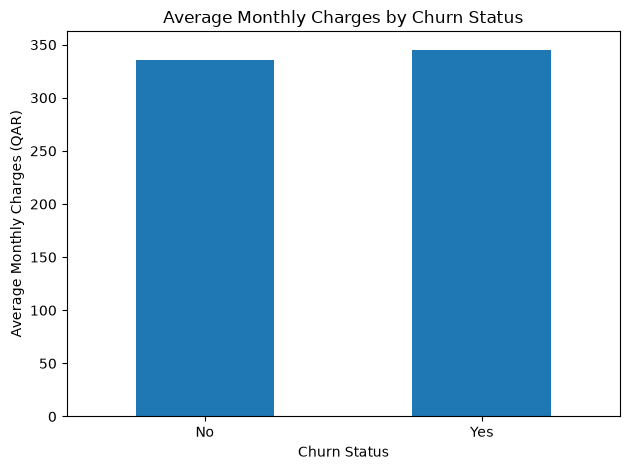

In [128]:
import matplotlib.pyplot as plt

charges_by_churn = (
    customer_analytics_df
    .groupby("churn")["monthly_charges_qar"]
    .mean()
)

charges_by_churn.plot(
    kind="bar",
    title="Average Monthly Charges by Churn Status",
    xlabel="Churn Status",
    ylabel="Average Monthly Charges (QAR)"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### b. Churn rate by contract type

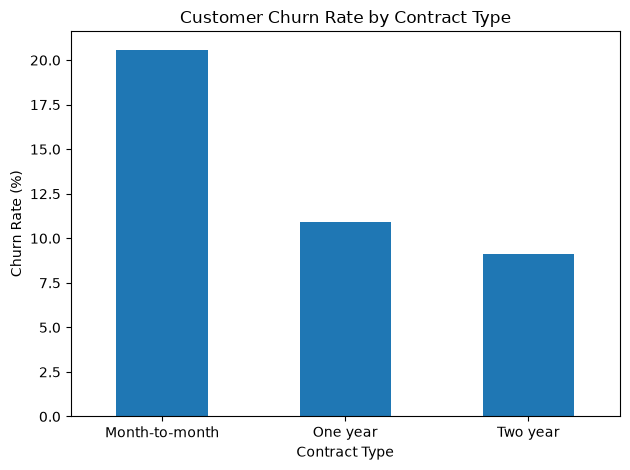

In [129]:

# Calculate churn percentages by contract type
contract_churn_pct = pd.crosstab(
    customer_analytics_df["contract_type"],
    customer_analytics_df["churn"],
    normalize="index"
).mul(100)

# Select only the churned customers
churn_rates = contract_churn_pct["Yes"].sort_values(
    ascending=False
)

# Create the chart
churn_rates.plot(
    kind="bar",
    title="Customer Churn Rate by Contract Type",
    xlabel="Contract Type",
    ylabel="Churn Rate (%)"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### 10. investigate revenue at risk

How much monthly revenue is associated with churned customers.

In [130]:
revenue_at_risk = customer_analytics_df.loc[
    customer_analytics_df["churn"] == "Yes",
    "monthly_charges_qar"
].sum()

print(
    "Monthly revenue associated with churned customers: "
    f"QAR {revenue_at_risk:,.2f}"
)

Monthly revenue associated with churned customers: QAR 658,153.09


A retention team could prioritize customers at risk of leaving and estimate the financial value of retaining them. However, the company should measure actual retained revenue and the cost of incentives before claiming that a campaign has generated savings.

#### 11.Estimate the value of a retention opportunity

In [131]:
# Number of churned customers
churned_customers = (
    customer_analytics_df["churn"] == "Yes"
).sum()

# Assume a 10% retention opportunity
customers_to_retain = churned_customers * 0.10

# Average monthly charge among churned customers
average_churned_charge = (
    customer_analytics_df.loc[
        customer_analytics_df["churn"] == "Yes",
        "monthly_charges_qar"
    ].mean()
)

# Estimated monthly charges associated with retained customers
retention_opportunity = (
    customers_to_retain * average_churned_charge
)

print("Churned customers:", churned_customers)
print("10% retention scenario:", round(customers_to_retain))
print(
    "Estimated monthly charges retained: "
    f"QAR {retention_opportunity:,.2f}"
)

Churned customers: 1906
10% retention scenario: 191
Estimated monthly charges retained: QAR 65,815.31


If the company could have retained approximately 10% of these 1,906 customers, and those customers had representative average monthly charges, the associated monthly charges would be about QAR 65,815.
That is a scenario, not guaranteed savings or profit. A real retention campaign would need to account for campaign costs, customer response rates, and how long customers remain.

### Machine Learning

#### 1. Define the features and target

In [132]:
# Features: information used to predict churn
X = customer_analytics_df.drop(
    columns=["customer_id", "churn"]
)

# Target: what the model predicts
y = customer_analytics_df["churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFeature data types:")
print(X.dtypes)

Features shape: (12000, 25)
Target shape: (12000,)

Target distribution:
churn
No     10094
Yes     1906
Name: count, dtype: int64

Feature data types:
gender                               str
age                              float64
city                                 str
plan_type                            str
contract_type                        str
tenure_months                      int64
internet_service                     str
device_type                          str
auto_pay                             str
family_lines                       int64
roaming                              str
voice_minutes_monthly            float64
data_usage_gb_monthly            float64
sms_count_monthly                float64
international_minutes_monthly    float64
dropped_calls_monthly            float64
network_incidents                float64
monthly_charges_qar              float64
total_charges_qar                float64
payment_delay_count              float64
complaints_count            

#### 2. Split the data into training and testing sets

In [135]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training features: (9600, 25)
Testing features: (2400, 25)

Training target distribution:
churn
No     84.11
Yes    15.89
Name: proportion, dtype: float64

Testing target distribution:
churn
No     84.12
Yes    15.88
Name: proportion, dtype: float64


#### 3. Prepare numerical and categorical features

OneHotEncoder to convert categorical values into numerical columns.

StandardScaler to scale numerical features.

ColumnTransformer to apply the correct transformation to each group.

In [136]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify categorical columns
categorical_columns = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Identify numerical columns
numerical_columns = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:", categorical_columns)
print("\nNumber of categorical columns:", len(categorical_columns))

print("\nNumerical columns:", numerical_columns)
print("\nNumber of numerical columns:", len(numerical_columns))

Categorical columns: ['gender', 'city', 'plan_type', 'contract_type', 'internet_service', 'device_type', 'auto_pay', 'roaming']

Number of categorical columns: 8

Numerical columns: ['age', 'tenure_months', 'family_lines', 'voice_minutes_monthly', 'data_usage_gb_monthly', 'sms_count_monthly', 'international_minutes_monthly', 'dropped_calls_monthly', 'network_incidents', 'monthly_charges_qar', 'total_charges_qar', 'payment_delay_count', 'complaints_count', 'support_contacts', 'usage_data_missing', 'billing_data_missing', 'support_data_missing']

Number of numerical columns: 17


#### 4. Create the preprocessing transformer

In [137]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_columns
        )
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


#### 5. Build and train Logistic Regression -  Baseline

In [138]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create the complete machine learning pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


#### 6. Evaluate the model

In [139]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Make predictions on unseen test data
y_pred = logistic_model.predict(X_test)

# Get the predicted probability of churn = Yes
print("Model classes:", logistic_model.classes_)

yes_index = list(logistic_model.classes_).index("Yes")
y_proba = logistic_model.predict_proba(X_test)[:, yes_index]

# Evaluate the model
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=["No", "Yes"]))

print(
    "\nROC-AUC:",
    round(roc_auc_score((y_test == "Yes").astype(int), y_proba), 4)
)

Model classes: ['No' 'Yes']
Accuracy: 0.5625

Classification Report:
              precision    recall  f1-score   support

          No       0.88      0.56      0.68      2019
         Yes       0.20      0.59      0.30       381

    accuracy                           0.56      2400
   macro avg       0.54      0.57      0.49      2400
weighted avg       0.77      0.56      0.62      2400

Confusion Matrix:
[[1127  892]
 [ 158  223]]

ROC-AUC: 0.6049


Model classes: ['No' 'Yes']

This tells us the model recognizes two possible outcomes:
- No: customer does not churn.
- Yes: customer churns.
We check the order because we will soon extract the probability of churn specifically, rather than the probability of staying.

- : means select every row.
- yes_index means select the column containing the probability of Yes.
The result, y_proba, contains one churn probability per test customer.

#### Model 2: Decision Tree Classifier

In [140]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

In [141]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                class_weight="balanced",
                max_depth=6,
                random_state=42
            )
        )
    ]
)

print("Decision Tree pipeline created successfully!")

Decision Tree pipeline created successfully!


In [142]:
decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


#### Evaluate the model

In [143]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_tree = decision_tree_model.predict(X_test)

print("Decision Tree Accuracy:",
      round(accuracy_score(y_test, y_pred_tree), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree, zero_division=0))

Decision Tree Accuracy: 0.5058

Classification Report:
              precision    recall  f1-score   support

          No       0.88      0.48      0.62      2019
         Yes       0.19      0.65      0.30       381

    accuracy                           0.51      2400
   macro avg       0.54      0.57      0.46      2400
weighted avg       0.77      0.51      0.57      2400



#### Model 3: Random Forest

In [144]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced",
                max_depth=12,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest pipeline created successfully!")

random_forest_model.fit(X_train, y_train)
print("Random Forest trained successfully!")

Random Forest pipeline created successfully!
Random Forest trained successfully!


#### Evaluating the model

In [145]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Predict churn for unseen customers
y_pred_rf = random_forest_model.predict(X_test)

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(
    y_test, y_pred_rf, pos_label="Yes", zero_division=0
)
rf_recall = recall_score(
    y_test, y_pred_rf, pos_label="Yes", zero_division=0
)
rf_f1 = f1_score(
    y_test, y_pred_rf, pos_label="Yes", zero_division=0
)

print("Random Forest Results")
print("---------------------")
print("Accuracy:", round(rf_accuracy, 4))
print("Churn Precision:", round(rf_precision, 4))
print("Churn Recall:", round(rf_recall, 4))
print("Churn F1-score:", round(rf_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf, labels=["No", "Yes"]))

Random Forest Results
---------------------
Accuracy: 0.6808
Churn Precision: 0.2114
Churn Recall: 0.3701
Churn F1-score: 0.2691

Classification Report:
              precision    recall  f1-score   support

          No       0.86      0.74      0.80      2019
         Yes       0.21      0.37      0.27       381

    accuracy                           0.68      2400
   macro avg       0.54      0.55      0.53      2400
weighted avg       0.76      0.68      0.71      2400

Confusion Matrix:
[[1493  526]
 [ 240  141]]


Model	Accuracy	Churn precision	Churn recall	Churn F1

Logistic Regression	56.25%	20%	59%	0.30
Decision Tree	50.58%	19%	65%	0.30
Random Forest	68.08%	21.14%	37.01%	0.27

Interpretation: Random Forest has the highest accuracy, but Decision Tree catches the largest proportion of churners. Logistic Regression offers a middle ground on recall.
None is a strong churn model yet. The right choice depends on the cost of missed churners versus unnecessary retention campaigns.

#### 5. Gradient Boosting

In [146]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            GradientBoostingClassifier(
                n_estimators=100,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting trained successfully!")

Gradient Boosting trained successfully!


#### Evaluate

In [147]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

y_pred_gb = gradient_boosting_model.predict(X_test)

gb_classes = list(gradient_boosting_model.classes_)
gb_yes_index = gb_classes.index("Yes")

y_proba_gb = gradient_boosting_model.predict_proba(X_test)[:, gb_yes_index]

print("Gradient Boosting Accuracy:",
      round(accuracy_score(y_test, y_pred_gb), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb, labels=["No", "Yes"]))

print("ROC-AUC:",
      round(roc_auc_score((y_test == "Yes").astype(int), y_proba_gb), 4))

Gradient Boosting Accuracy: 0.8404

Classification Report:
              precision    recall  f1-score   support

          No       0.84      1.00      0.91      2019
         Yes       0.00      0.00      0.00       381

    accuracy                           0.84      2400
   macro avg       0.42      0.50      0.46      2400
weighted avg       0.71      0.84      0.77      2400

Confusion Matrix:
[[2017    2]
 [ 381    0]]
ROC-AUC: 0.6004


In [148]:
# Check how churn relates to contract type
print("Churn rate by contract type:")

print(
    customer_analytics_df.groupby("contract_type", observed=True)["churn"]
    .apply(lambda x: (x == "Yes").mean())
    .sort_values(ascending=False)
    .round(4)
)

# Check the overall target distribution
print("\nOverall churn distribution:")
print(customer_analytics_df["churn"].value_counts(normalize=True).round(4))

Churn rate by contract type:
contract_type
Month-to-month    0.2059
One year          0.1090
Two year          0.0910
Name: churn, dtype: float64

Overall churn distribution:
churn
No     0.8412
Yes    0.1588
Name: proportion, dtype: float64


#### Check whether our models use churn probabilities effectively

A model can assign higher churn probabilities to at-risk customers but still predict No for everyone if its default decision threshold is too high.

In [150]:
import pandas as pd

# Get predicted probabilities for churn
gb_probabilities = gradient_boosting_model.predict_proba(X_test)

# Find the column corresponding to "Yes"
yes_index = list(gradient_boosting_model.classes_).index("Yes")

# Extract churn probabilities
churn_probabilities = gb_probabilities[:, yes_index]

# Summarize the probabilities
print("Churn probability summary:")
print(pd.Series(churn_probabilities).describe().round(4))

# Compare probabilities for actual churners and non-churners
probability_check = pd.DataFrame({
    "Actual_Churn": y_test.to_numpy(),
    "Churn_Probability": churn_probabilities
})

print("\nAverage predicted probability by actual outcome:")
print(
    probability_check.groupby("Actual_Churn")["Churn_Probability"]
    .mean()
    .round(4)
)

Churn probability summary:
count    2400.0000
mean        0.1580
std         0.0641
min         0.0390
25%         0.1029
50%         0.1536
75%         0.2001
max         0.6017
dtype: float64

Average predicted probability by actual outcome:
Actual_Churn
No     0.1548
Yes    0.1752
Name: Churn_Probability, dtype: float64


In [151]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Set an experimental churn threshold
threshold = 0.15

# Convert probabilities into Yes/No predictions
y_pred_gb_15 = [
    "Yes" if probability >= threshold else "No"
    for probability in churn_probabilities
]

# Evaluate predictions
print("Threshold:", threshold)
print("Accuracy:", round(accuracy_score(y_test, y_pred_gb_15), 4))

print(
    "Churn Precision:",
    round(precision_score(
        y_test, y_pred_gb_15, pos_label="Yes", zero_division=0
    ), 4)
)

print(
    "Churn Recall:",
    round(recall_score(
        y_test, y_pred_gb_15, pos_label="Yes", zero_division=0
    ), 4)
)

print(
    "Churn F1-score:",
    round(f1_score(
        y_test, y_pred_gb_15, pos_label="Yes", zero_division=0
    ), 4)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb_15, labels=["No", "Yes"]))

print("\nPredicted class counts:")
print(pd.Series(y_pred_gb_15).value_counts())

Threshold: 0.15
Accuracy: 0.5225
Churn Precision: 0.1942
Churn Recall: 0.6378
Churn F1-score: 0.2978

Confusion Matrix:
[[1011 1008]
 [ 138  243]]

Predicted class counts:
Yes    1251
No     1149
Name: count, dtype: int64


Let's check whether the Decision Tree is relying on sensible customer features

In [152]:
# Get the trained Decision Tree from the pipeline
tree = decision_tree_model.named_steps["classifier"]

# Get the transformed feature names
feature_names = (
    decision_tree_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Create a feature importance table
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree.feature_importances_
})

# Sort from most important to least important
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_df.head(15).to_string(index=False))

                                  Feature  Importance
categorical__contract_type_Month-to-month    0.342810
             numerical__total_charges_qar    0.138183
           numerical__monthly_charges_qar    0.084460
         numerical__data_usage_gb_monthly    0.080786
             numerical__sms_count_monthly    0.057553
                 categorical__auto_pay_No    0.052208
         numerical__voice_minutes_monthly    0.043884
                           numerical__age    0.039455
 numerical__international_minutes_monthly    0.036182
                 numerical__tenure_months    0.026633
                  numerical__family_lines    0.018101
          categorical__plan_type_Standard    0.015404
              numerical__support_contacts    0.014083
              numerical__complaints_count    0.012970
         categorical__device_type_Android    0.011364


#### Compare feature importance with actual churn rates

Let's investigate monthly charges and total charges directly rather than relying only on the tree's importance scores.

In [153]:
# Compare numerical feature averages by churn outcome
features_to_check = [
    "total_charges_qar",
    "monthly_charges_qar",
    "data_usage_gb_monthly",
    "sms_count_monthly",
    "tenure_months"
]

print(
    customer_analytics_df.groupby("churn")[features_to_check]
    .mean()
    .round(2)
    .T
)

churn                        No       Yes
total_charges_qar      12244.50  11646.63
monthly_charges_qar      335.20    345.31
data_usage_gb_monthly     16.44     17.00
sms_count_monthly         64.90     64.92
tenure_months             37.21     34.46


In [154]:
from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_train_sub.shape)
print("Validation set:", X_val.shape)

print("\nTraining churn proportions:")
print(y_train_sub.value_counts(normalize=True).round(4))

print("\nValidation churn proportions:")
print(y_val.value_counts(normalize=True).round(4))

Training subset: (7680, 25)
Validation set: (1920, 25)

Training churn proportions:
churn
No     0.8411
Yes    0.1589
Name: proportion, dtype: float64

Validation churn proportions:
churn
No     0.8411
Yes    0.1589
Name: proportion, dtype: float64


#### Train Logistic Regression on the training subset

In [155]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create a fresh model
logistic_tuned = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

# Train using only the training subset
logistic_tuned.fit(X_train_sub, y_train_sub)

print("Logistic Regression trained on training subset!")

Logistic Regression trained on training subset!


#### Generate validation probabilities

In [156]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Get the probability of churn for each validation customer
classes = list(logistic_tuned.classes_)
yes_index = classes.index("Yes")

y_val_proba = logistic_tuned.predict_proba(X_val)[:, yes_index]

print("First 10 churn probabilities:")
print(y_val_proba[:10].round(4))

First 10 churn probabilities:
[0.5488 0.4813 0.5865 0.3525 0.6222 0.564  0.2582 0.3632 0.6361 0.6416]


#### Compare thresholds

In [157]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Convert actual churn labels to binary values
y_val_binary = (y_val == "Yes").astype(int)

# Thresholds to compare
thresholds = [0.20, 0.30, 0.40, 0.50]

results = []

for threshold in thresholds:

    # Predict Yes if probability meets the threshold
    y_val_pred = (y_val_proba >= threshold).astype(int)

    # Calculate metrics
    precision = precision_score(
        y_val_binary, y_val_pred, zero_division=0
    )
    recall = recall_score(
        y_val_binary, y_val_pred, zero_division=0
    )
    f1 = f1_score(
        y_val_binary, y_val_pred, zero_division=0
    )

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Customers_Flagged": int(y_val_pred.sum())
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score  Customers_Flagged
       0.2     0.1590  0.9967    0.2742               1912
       0.3     0.1694  0.9607    0.2880               1730
       0.4     0.1939  0.8393    0.3151               1320
       0.5     0.2238  0.6590    0.3342                898


#### Evaluate on the untouched test set

In [158]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Create a fresh pipeline
logistic_final = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

# Train on the full training set
logistic_final.fit(X_train, y_train)

# Get churn probabilities on the untouched test set
classes = list(logistic_final.classes_)
yes_index = classes.index("Yes")
test_probabilities = logistic_final.predict_proba(X_test)[:, yes_index]

# Apply our candidate threshold
threshold = 0.50
y_pred_final = [
    "Yes" if probability >= threshold else "No"
    for probability in test_probabilities
]

# Evaluate
print("Test Accuracy:", round(accuracy_score(y_test, y_pred_final), 4))
print("Churn Precision:", round(
    precision_score(y_test, y_pred_final, pos_label="Yes", zero_division=0), 4
))
print("Churn Recall:", round(
    recall_score(y_test, y_pred_final, pos_label="Yes", zero_division=0), 4
))
print("Churn F1-score:", round(
    f1_score(y_test, y_pred_final, pos_label="Yes", zero_division=0), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final, labels=["No", "Yes"]))

Test Accuracy: 0.5625
Churn Precision: 0.2
Churn Recall: 0.5853
Churn F1-score: 0.2981

Classification Report:
              precision    recall  f1-score   support

          No       0.88      0.56      0.68      2019
         Yes       0.20      0.59      0.30       381

    accuracy                           0.56      2400
   macro avg       0.54      0.57      0.49      2400
weighted avg       0.77      0.56      0.62      2400

Confusion Matrix:
[[1127  892]
 [ 158  223]]


#### Tune the Decision Tree

In [160]:
from sklearn.metrics import make_scorer, f1_score
from sklearn.model_selection import GridSearchCV

# Tell Scikit-learn that "Yes" is the positive class
churn_f1_scorer = make_scorer(
    f1_score,
    pos_label="Yes"
)

# Repeat hyperparameter tuning with the corrected scorer
grid_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=param_grid,
    scoring=churn_f1_scorer,
    cv=3,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

grid_search.fit(X_train, y_train)

print("\nBest parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(grid_search.best_score_, 4))

Fitting 3 folds for each of 108 candidates, totalling 324 fits

Best parameters:
{'classifier__criterion': 'entropy', 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}

Best cross-validation F1-score:
0.3195


#### Evaluate the tuned model

In [161]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Get the best tuned pipeline
best_tree_model = grid_search.best_estimator_

# Predict on the untouched test set
y_pred_tuned = best_tree_model.predict(X_test)

print("Tuned Decision Tree Accuracy:",
      round(accuracy_score(y_test, y_pred_tuned), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned, labels=["No", "Yes"]))

Tuned Decision Tree Accuracy: 0.5062

Classification Report:
              precision    recall  f1-score   support

          No       0.88      0.48      0.62      2019
         Yes       0.19      0.67      0.30       381

    accuracy                           0.51      2400
   macro avg       0.54      0.57      0.46      2400
weighted avg       0.77      0.51      0.57      2400

Confusion Matrix:
[[ 960 1059]
 [ 126  255]]


#### Save model

In [165]:
import joblib

# Save the tuned Decision Tree inside the models folder
joblib.dump(
    best_tree_model,
    "../models/best_telecom_churn_model.pkl"
)

print("Model saved successfully in the models folder!")

Model saved successfully in the models folder!
